# Reward omission response

Reward-responsive neurons are selected from Correct trials with the same
circular-shift permutation method used in `neuron_selection.ipynb`.

Within the reward-zone window, the two changes are:

$$
\Delta A_i=A^{\mathrm{peak}}_{i,O}-A^{\mathrm{peak}}_{i,C},\qquad
\Delta P_i=P^{\mathrm{peak}}_{i,O}-P^{\mathrm{peak}}_{i,C}.
$$

Each Correct reference sample contains the same number of trials as NoReward.
Tracks are averaged equally after computing each change.


In [103]:
from pathlib import Path
import os
import re
import sys
import zlib

from joblib import Parallel, delayed, parallel_backend
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import ipywidgets as widgets
from IPython.display import clear_output, display
import numpy as np
import pandas as pd


REPO_ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / 'src/HPC_2P_analysis').is_dir()
)
if str(REPO_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / 'src'))

from HPC_2P_analysis.utils.config import (
    get_data_track_type,
    get_one_index,
    resolve_type_patterns,
)
from HPC_2P_analysis.utils.loadData import load_screen_data


In [104]:
# Key parameters
FILE_PATH = "/home/wangym/code/ZhaoLab-analysis-python/data/HPC_2p/screen/HPC14/HPC14_2025-05-24_75_position_screen.pkl"
TRACKS = ('*',)
REWARD_WINDOW_MARGIN_CM = 20.0

SCREEN_N_MERGED_BINS = 8
SCREEN_MIN_TRIALS = 5
SCREEN_WINSOR_N = 1
SCREEN_N_PERM = 5000
SCREEN_ALPHA = 0.01
SCREEN_BASELINE_METHOD = 'median'
SCREEN_ALTERNATIVE = 'two-sided'
SCREEN_N_JOBS = -1
SCREEN_BACKEND = 'loky'

N_REFERENCE_REPEATS = 500
N_DISTRIBUTION_BINS = 21
N_TOP_NEURONS = 10
RANDOM_SEED = 20261101

CORRECT_COLOR = '#8f8f8f'
NOREWARD_COLOR = '#CE8590'
ZONE_COLOR = '#7A1F36'
NEURON_FIGSIZE = (6.8, 3.6)
SAVE_FIGURE_DPI = 300
SAVE_FIGURE_FORMAT = 'png'
SHOW_INTERACTIVE_BROWSER = True


In [105]:
def load_analysis_file(file_path):
    """Load unmasked neurons from one neuron-selection screen pickle."""
    file_path = Path(file_path)
    if file_path.suffix.lower() not in {'.pkl', '.pickle'}:
        raise ValueError('FILE_PATH must be a neuron-selection screen pickle.')
    return load_screen_data(file_path, screen_mode='raw')


def stable_seed(*parts):
    """Return a reproducible seed independent of Python hash randomization."""
    token = '|'.join(map(str, parts)).encode('utf-8')
    return int((RANDOM_SEED + zlib.crc32(token)) % (2**32 - 1))


def expected_reward_zone_index(data, track):
    """Return the zero-based rewarded-zone index for one track."""
    task_type = str(data['file_info']['task_type'])
    track_name = str(track)

    if track_name.startswith('couple_'):
        return 2
    if task_type in {'couple', 'position', 'first_position'}:
        return 2
    if task_type in {'pattern', 'first_pattern'}:
        core = track_name.removeprefix('couple_')
        if len(core) == 3 and 'C' in core:
            return 2 * core.index('C')

    raise ValueError(
        f'Cannot infer reward zone for task={task_type!r}, track={track!r}.'
    )


def reward_window_bounds(zones, reward_zone_index, n_position):
    """Expand the reward-zone boundaries by the configured margin."""
    zones = np.asarray(zones, dtype=float)
    reward_start, reward_end = zones[int(reward_zone_index)]
    margin_bins = REWARD_WINDOW_MARGIN_CM / 2.0
    start = int(np.ceil(reward_start - margin_bins))
    end = int(np.floor(reward_end + margin_bins)) + 1
    return max(0, start), min(int(n_position), end)


def prepare_analysis_data(data):
    """Collect Correct and NoReward trials and their reward windows."""
    task_type = str(data['file_info']['task_type'])
    if task_type not in {'position', 'couple'}:
        raise ValueError(
            'Reward omission analysis only supports position and couple '
            f'rules; got task_type={task_type!r}.'
        )
    tracks = resolve_type_patterns(TRACKS, get_data_track_type(data))
    prepared = {}
    summary_rows = []
    skipped_rows = []

    for track in tracks:
        correct_index = get_one_index(data, track, 'Correct')
        noreward_index = get_one_index(data, track, 'NoReward')
        correct = data['firing'][correct_index]
        no_reward = data['firing'][noreward_index]
        n_correct = 0 if correct is None else correct.shape[1]
        n_no_reward = 0 if no_reward is None else no_reward.shape[1]

        if n_no_reward == 0:
            skipped_rows.append({
                'track': track,
                'n_correct': n_correct,
                'n_noreward': n_no_reward,
                'reason': 'No NoReward trials.',
            })
            continue
        if n_correct < SCREEN_MIN_TRIALS:
            skipped_rows.append({
                'track': track,
                'n_correct': n_correct,
                'n_noreward': n_no_reward,
                'reason': (
                    f'Correct trials below SCREEN_MIN_TRIALS='
                    f'{SCREEN_MIN_TRIALS}.'
                ),
            })
            continue
        if n_correct < n_no_reward:
            skipped_rows.append({
                'track': track,
                'n_correct': n_correct,
                'n_noreward': n_no_reward,
                'reason': 'Correct trials fewer than NoReward trials.',
            })
            continue

        reward_zone_index = expected_reward_zone_index(data, track)
        start, end = reward_window_bounds(
            data['zones'], reward_zone_index, correct.shape[2]
        )
        prepared[track] = {
            'correct': correct,
            'noreward': no_reward,
            'window_start': start,
            'window_end': end,
            'reward_zone_index': reward_zone_index,
        }
        summary_rows.append({
            'track': track,
            'n_correct': n_correct,
            'n_noreward': n_no_reward,
            'reward_zone': reward_zone_index + 1,
            'window_start_bin': start,
            'window_end_bin': end,
            'window_bins': end - start,
        })

    if not prepared:
        details = pd.DataFrame(skipped_rows).to_string(index=False)
        raise ValueError(f'No track can be analyzed.\n{details}')

    return (
        data,
        prepared,
        pd.DataFrame(summary_rows),
        pd.DataFrame(skipped_rows),
    )


In [106]:
def merge_position_bins(firing, n_merged_bins):
    """Average adjacent spatial bins as in neuron_selection.ipynb."""
    groups = np.array_split(
        np.arange(firing.shape[2]),
        min(int(n_merged_bins), firing.shape[2]),
    )
    return np.stack(
        [np.mean(firing[:, :, group], axis=2) for group in groups],
        axis=2,
    )


def trial_baseline_correct(firing):
    """Subtract the configured spatial baseline from every neuron-trial."""
    if SCREEN_BASELINE_METHOD == 'none':
        return firing.astype(float, copy=True)
    if SCREEN_BASELINE_METHOD == 'median':
        baseline = np.median(firing, axis=2, keepdims=True)
    elif SCREEN_BASELINE_METHOD == 'mean':
        baseline = np.mean(firing, axis=2, keepdims=True)
    else:
        raise ValueError(
            f'Unknown SCREEN_BASELINE_METHOD={SCREEN_BASELINE_METHOD!r}.'
        )
    return firing - baseline


def winsorize_trial_axis(values):
    """Winsorize each neuron-bin across trials."""
    if SCREEN_WINSOR_N <= 0:
        return values.astype(float, copy=True)
    sorted_values = np.sort(values, axis=1)
    lower = np.take(
        sorted_values, SCREEN_WINSOR_N, axis=1
    )[:, None, :]
    upper = np.take(
        sorted_values,
        values.shape[1] - SCREEN_WINSOR_N - 1,
        axis=1,
    )[:, None, :]
    return np.clip(values, lower, upper)


def winsorized_t_map(values):
    """Compute the neuron-selection t-like map."""
    winsorized = winsorize_trial_axis(values)
    mean = winsorized.mean(axis=1)
    standard_error = np.maximum(
        winsorized.std(axis=1, ddof=1), 1e-8
    ) / np.sqrt(values.shape[1])
    return mean / standard_error


def max_statistic(t_map):
    """Return the same spatial max statistic used by neuron selection."""
    if SCREEN_ALTERNATIVE == 'greater':
        return np.max(t_map, axis=1)
    if SCREEN_ALTERNATIVE == 'two-sided':
        return np.max(np.abs(t_map), axis=1)
    if SCREEN_ALTERNATIVE == 'less':
        return -np.min(t_map, axis=1)
    raise ValueError(f'Unknown SCREEN_ALTERNATIVE={SCREEN_ALTERNATIVE!r}.')


def circular_shift_trials(values, rng):
    """Circularly shift each neuron-trial independently across position."""
    n_neuron, n_trial, n_bin = values.shape
    shifts = rng.integers(0, n_bin, size=(n_neuron, n_trial))
    indices = (
        np.arange(n_bin)[None, None, :] - shifts[:, :, None]
    ) % n_bin
    return np.take_along_axis(values, indices, axis=2)


def screen_reward_track(track, track_data):
    """Run the neuron-selection permutation test within one reward window."""
    start = track_data['window_start']
    end = track_data['window_end']
    firing = track_data['correct'][:, :, start:end]
    values = trial_baseline_correct(firing)
    observed_values = merge_position_bins(
        values, SCREEN_N_MERGED_BINS
    )

    observed = max_statistic(winsorized_t_map(observed_values))
    exceed = np.zeros(values.shape[0], dtype=int)
    rng = np.random.default_rng(stable_seed('reward-screen', track))

    for _ in range(SCREEN_N_PERM):
        permuted = circular_shift_trials(values, rng)
        permuted = merge_position_bins(
            permuted, SCREEN_N_MERGED_BINS
        )
        permuted_statistic = max_statistic(winsorized_t_map(permuted))
        exceed += permuted_statistic >= observed

    p_values = (exceed + 1) / (SCREEN_N_PERM + 1)
    return {
        'track': track,
        'p_values': p_values,
        'observed_statistic': observed,
    }


def screen_reward_neurons(data, prepared):
    """Screen tracks in parallel and Bonferroni-correct across tracks."""
    tasks = list(prepared.items())
    if SCREEN_N_JOBS is None:
        requested_jobs = os.cpu_count() or 1
    elif SCREEN_N_JOBS < 0:
        requested_jobs = os.cpu_count() or 1
    else:
        requested_jobs = int(SCREEN_N_JOBS)
    n_workers = min(max(1, requested_jobs), len(tasks))

    print(
        f'[Reward screening] tracks={len(tasks)}, workers={n_workers}, '
        f'backend={SCREEN_BACKEND}, permutations={SCREEN_N_PERM}'
    )
    if n_workers == 1:
        track_results = [
            screen_reward_track(track, track_data)
            for track, track_data in tasks
        ]
    elif SCREEN_BACKEND == 'loky':
        with parallel_backend('loky', inner_max_num_threads=1):
            track_results = Parallel(n_jobs=n_workers)(
                delayed(screen_reward_track)(track, track_data)
                for track, track_data in tasks
            )
    else:
        track_results = Parallel(
            n_jobs=n_workers, backend=SCREEN_BACKEND
        )(
            delayed(screen_reward_track)(track, track_data)
            for track, track_data in tasks
        )

    p_matrix = np.stack(
        [result['p_values'] for result in track_results], axis=0
    )
    minimum_p = np.min(p_matrix, axis=0)
    corrected_p = np.minimum(minimum_p * len(track_results), 1.0)
    reward_responsive = corrected_p < SCREEN_ALPHA
    corrected_threshold = SCREEN_ALPHA / len(track_results)
    significant_tracks = [
        tuple(
            result['track']
            for result in track_results
            if result['p_values'][cell_index] < corrected_threshold
        )
        for cell_index in range(len(data['cell_ids']))
    ]

    table = pd.DataFrame({
        'row_index': np.arange(len(data['cell_ids']), dtype=int),
        'cell_id': np.asarray(data['cell_ids']),
        'reward_p_min': minimum_p,
        'reward_p_corrected': corrected_p,
        'significant_tracks': significant_tracks,
        'reward_responsive': reward_responsive,
    })
    return table, track_results


In [107]:
def peak_features(mean_maps):
    """Return the maximum amplitude and its position in the window."""
    peak_index = np.argmax(mean_maps, axis=1)
    peak_amplitude = np.take_along_axis(
        mean_maps, peak_index[:, None], axis=1
    ).ravel()
    peak_position_cm = peak_index.astype(float) * 2.0
    return peak_amplitude, peak_position_cm


def finite_track_mean(values):
    """Average tracks equally without replacing invalid values."""
    values = np.asarray(values, dtype=float)
    valid = np.isfinite(values)
    count = valid.sum(axis=0)
    total = np.where(valid, values, 0.0).sum(axis=0)
    mean = np.full(values.shape[1], np.nan, dtype=float)
    mean[count > 0] = total[count > 0] / count[count > 0]
    return mean, count


def reference_mean_std(reference):
    """Return per-neuron mean and sample SD across Correct draws."""
    mean = np.nanmean(reference, axis=0)
    std = np.nanstd(reference, axis=0, ddof=1)
    return mean, std


def compute_feature_changes(data, prepared, reward_table):
    """Compare peak amplitude and position with Correct references."""
    n_cells = len(data['cell_ids'])
    amplitude_tracks = []
    position_tracks = []
    reference_amplitude = np.full(
        (N_REFERENCE_REPEATS, n_cells), np.nan, dtype=float
    )
    reference_position = np.full_like(reference_amplitude, np.nan)

    correct_features = {}
    for track, track_data in prepared.items():
        start = track_data['window_start']
        end = track_data['window_end']
        correct = track_data['correct'][:, :, start:end]
        no_reward = track_data['noreward'][:, :, start:end]
        correct_amplitude, correct_position = peak_features(
            correct.mean(axis=1)
        )
        noreward_amplitude, noreward_position = peak_features(
            no_reward.mean(axis=1)
        )
        correct_features[track] = (
            correct_amplitude,
            correct_position,
        )
        amplitude_tracks.append(noreward_amplitude - correct_amplitude)
        position_tracks.append(noreward_position - correct_position)

    amplitude_change, valid_track_count = finite_track_mean(
        amplitude_tracks
    )
    position_shift, _ = finite_track_mean(position_tracks)

    for repeat in range(N_REFERENCE_REPEATS):
        repeat_amplitude = []
        repeat_position = []

        for track, track_data in prepared.items():
            start = track_data['window_start']
            end = track_data['window_end']
            correct = track_data['correct'][:, :, start:end]
            n_no_reward = track_data['noreward'].shape[1]
            rng = np.random.default_rng(
                stable_seed('correct-reference', repeat, track)
            )
            sample_index = rng.choice(
                correct.shape[1], size=n_no_reward, replace=False
            )

            correct_amplitude, correct_position = correct_features[track]
            sample_amplitude, sample_position = peak_features(
                correct[:, sample_index, :].mean(axis=1)
            )
            repeat_amplitude.append(
                sample_amplitude - correct_amplitude
            )
            repeat_position.append(sample_position - correct_position)

        reference_amplitude[repeat], _ = finite_track_mean(
            repeat_amplitude
        )
        reference_position[repeat], _ = finite_track_mean(
            repeat_position
        )

    reference_amplitude_mean, reference_amplitude_std = reference_mean_std(
        reference_amplitude
    )
    reference_position_mean, reference_position_std = reference_mean_std(
        reference_position
    )

    results = reward_table.copy()
    results['n_valid_tracks'] = valid_track_count
    results['peak_amplitude_change'] = amplitude_change
    results['reference_peak_amplitude_mean'] = reference_amplitude_mean
    results['reference_peak_amplitude_std'] = reference_amplitude_std
    results['absolute_peak_amplitude_change'] = np.abs(amplitude_change)
    results['peak_position_shift_cm'] = position_shift
    results['reference_peak_position_mean_cm'] = reference_position_mean
    results['reference_peak_position_std_cm'] = reference_position_std
    results['absolute_peak_position_shift_cm'] = np.abs(position_shift)
    results = results.loc[
        results['reward_responsive']
        & np.isfinite(results['peak_amplitude_change'])
        & np.isfinite(results['peak_position_shift_cm'])
    ].reset_index(drop=True)

    if results.empty:
        raise ValueError(
            'No reward-responsive neuron has valid peak features.'
        )

    reference_repeats = {
        'peak_amplitude_change': reference_amplitude,
        'peak_position_shift_cm': reference_position,
    }
    return results, reference_repeats


def run_reward_omission_analysis(file_path):
    """Run reward screening and omission-response analysis for one file."""
    file_path = Path(file_path)
    data = load_analysis_file(file_path)
    aligned, prepared, track_summary, skipped_tracks = prepare_analysis_data(
        data
    )
    reward_table, reward_track_results = screen_reward_neurons(
        aligned, prepared
    )
    cell_results, reference_repeats = compute_feature_changes(
        aligned, prepared, reward_table
    )
    top_amplitude_neurons = cell_results.nlargest(
        N_TOP_NEURONS, 'absolute_peak_amplitude_change'
    ).reset_index(drop=True)
    top_position_neurons = cell_results.nlargest(
        N_TOP_NEURONS, 'absolute_peak_position_shift_cm'
    ).reset_index(drop=True)

    return {
        'file_path': str(file_path),
        'data': aligned,
        'prepared_tracks': prepared,
        'track_summary': track_summary,
        'skipped_tracks': skipped_tracks,
        'reward_table': reward_table,
        'reward_track_results': reward_track_results,
        'cell_results': cell_results,
        'reference_repeats': reference_repeats,
        'top_amplitude_neurons': top_amplitude_neurons,
        'top_position_neurons': top_position_neurons,
    }


In [108]:
def distribution_edges(values, n_bins):
    """Create common full-range histogram bins for both distributions."""
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    low, high = values.min(), values.max()
    if np.isclose(low, high):
        padding = 0.05 if np.isclose(low, 0) else 0.05 * abs(low)
    else:
        padding = 0.03 * (high - low)
    return np.linspace(low - padding, high + padding, n_bins + 1)


def reference_histogram_stats(reference, row_indices, edges):
    """Return mean and SD of cell-fraction histograms across draws."""
    selected = reference[:, np.asarray(row_indices, dtype=int)]
    fractions = []
    for values in selected:
        values = values[np.isfinite(values)]
        if len(values) == 0:
            continue
        counts, _ = np.histogram(values, bins=edges)
        fractions.append(100 * counts / counts.sum())
    if not fractions:
        raise ValueError('Correct reference contains no finite values.')
    fractions = np.asarray(fractions)
    return fractions.mean(axis=0), fractions.std(axis=0, ddof=1)


def plot_feature_distributions(
    cell_results,
    reference_repeats,
    *,
    data=None,
    savefig=False,
    save_dir=None,
    save_format=SAVE_FIGURE_FORMAT,
    dpi=SAVE_FIGURE_DPI,
    show=True,
):
    """Plot and optionally save both feature distributions."""
    metrics = (
        (
            'peak_amplitude_change',
            'Peak amplitude change (NoReward − Correct)',
        ),
        (
            'peak_position_shift_cm',
            'Peak position shift (NoReward − Correct, cm)',
        ),
    )
    figure, axes = plt.subplots(1, 2, figsize=(9.4, 3.7))
    row_indices = cell_results['row_index'].to_numpy()

    for axis, (metric, label) in zip(axes, metrics):
        no_reward = cell_results[metric].to_numpy()
        reference = reference_repeats[metric][:, row_indices]
        edges = distribution_edges(
            np.r_[no_reward, reference.ravel()], N_DISTRIBUTION_BINS
        )
        centers = 0.5 * (edges[:-1] + edges[1:])
        reference_mean, reference_std = reference_histogram_stats(
            reference_repeats[metric], row_indices, edges
        )
        counts, _ = np.histogram(no_reward, bins=edges)
        noreward_fraction = 100 * counts / counts.sum()

        axis.plot(
            centers, reference_mean, color=CORRECT_COLOR,
            linewidth=2.2, label='Correct reference',
        )
        axis.fill_between(
            centers,
            np.maximum(0, reference_mean - reference_std),
            reference_mean + reference_std,
            color=CORRECT_COLOR,
            alpha=0.18,
            linewidth=0,
        )
        axis.plot(
            centers, noreward_fraction, color=NOREWARD_COLOR,
            linewidth=2.2, label='NoReward',
        )
        axis.axvline(0, color='k', linestyle='--', linewidth=1)
        axis.set_xlabel(label, fontsize=12)
        axis.set_ylabel(
            'Fraction of reward-responsive neurons (%)', fontsize=12
        )
        axis.tick_params(labelsize=11)
        axis.spines['top'].set_visible(False)
        axis.spines['right'].set_visible(False)
        axis.legend(frameon=False)

    figure.tight_layout()

    if savefig:
        if data is None:
            raise ValueError('data is required when savefig=True.')
        output_dir = (
            Path(save_dir)
            if save_dir is not None
            else REPO_ROOT / 'results' / 'temp'
        )
        output_dir.mkdir(parents=True, exist_ok=True)
        animal, session_date = reward_omission_file_label(data)
        extension = str(save_format).lower().lstrip('.')
        save_path = output_dir / (
            f'{animal}_{session_date}_reward_omission_distribution.'
            f'{extension}'
        )
        figure.savefig(
            save_path, dpi=dpi, bbox_inches='tight', format=extension
        )
        print(f'Saved figure: {save_path}')

    if show:
        plt.show()
    return figure


def plot_reward_omission_distributions(
    analysis_results,
    *,
    savefig=False,
    save_dir=None,
    save_format=SAVE_FIGURE_FORMAT,
    dpi=SAVE_FIGURE_DPI,
    show=True,
):
    """Plot distributions directly from analysis output."""
    return plot_feature_distributions(
        analysis_results['cell_results'],
        analysis_results['reference_repeats'],
        data=analysis_results['data'],
        savefig=savefig,
        save_dir=save_dir,
        save_format=save_format,
        dpi=dpi,
        show=show,
    )


def pooled_activity_across_tracks(prepared, behavior):
    """Pool all track trials, then return mean and trial-level SEM."""
    key = 'correct' if behavior == 'Correct' else 'noreward'
    pooled_trials = np.concatenate([
        track_data[key] for track_data in prepared.values()
    ], axis=1)
    mean = pooled_trials.mean(axis=1)
    sem = pooled_trials.std(axis=1, ddof=0) / np.sqrt(
        pooled_trials.shape[1]
    )
    return mean, sem, pooled_trials.shape[1]


def draw_reward_zone_blocks(axis, zones, zone_indices=(0, 2, 4)):
    """Draw selected reward-zone blocks above the activity axis."""
    for zone_index in zone_indices:
        if zone_index >= len(zones):
            continue
        start, end = np.asarray(zones[zone_index], dtype=float) * 2.0
        axis.axvline(start, color='k', linestyle='--', linewidth=0.8)
        axis.axvline(end, color='k', linestyle='--', linewidth=0.8)
        axis.add_patch(Rectangle(
            (start, 1.015),
            end - start,
            0.035,
            transform=axis.get_xaxis_transform(),
            facecolor=ZONE_COLOR,
            edgecolor='none',
            clip_on=False,
            zorder=6,
        ))


def reward_omission_file_label(data):
    """Return animal and date labels from standard file metadata."""
    file_info = data['file_info']
    candidates = [
        file_info.get('mouse_base_id'),
        file_info.get('mouse_id'),
        file_info.get('file_name'),
        file_info.get('file_path'),
    ]
    animal = 'unknown-animal'
    session_date = file_info.get('session_date')

    for candidate in candidates:
        if candidate is None:
            continue
        match = re.search(r'\b(HPC?\d+)\b', str(candidate), flags=re.I)
        if match is not None:
            animal = match.group(1).upper()
            break

    if session_date is None:
        for candidate in candidates:
            if candidate is None:
                continue
            match = re.search(
                r'(?<!\d)((?:19|20)\d{2})[-_]?([01]\d)[-_]?([0-3]\d)(?!\d)',
                str(candidate),
            )
            if match is not None:
                session_date = '-'.join(match.groups())
                break
    if session_date is None:
        session_date = 'unknown-date'
    return animal, str(session_date)


def plot_reward_omission_neuron(
    data,
    prepared,
    neuron_id,
    *,
    figsize=NEURON_FIGSIZE,
    savefig=False,
    save_dir=None,
    save_format=SAVE_FIGURE_FORMAT,
    dpi=SAVE_FIGURE_DPI,
    show=True,
):
    """Plot track-equal Correct and NoReward activity for one neuron."""
    neuron_id = int(neuron_id)
    correct, correct_sem, n_correct = pooled_activity_across_tracks(
        prepared, 'Correct'
    )
    no_reward, noreward_sem, n_noreward = pooled_activity_across_tracks(
        prepared, 'NoReward'
    )
    position_cm = np.arange(correct.shape[1]) * 2.0

    figure, axis = plt.subplots(figsize=figsize)
    axis.plot(
        position_cm, correct[neuron_id], color=CORRECT_COLOR,
        linewidth=2.2, label=f'Correct (n={n_correct})',
    )
    axis.fill_between(
        position_cm,
        correct[neuron_id] - correct_sem[neuron_id],
        correct[neuron_id] + correct_sem[neuron_id],
        color=CORRECT_COLOR, alpha=0.18, linewidth=0,
    )
    axis.plot(
        position_cm, no_reward[neuron_id], color=NOREWARD_COLOR,
        linewidth=2.2, label=f'NoReward (n={n_noreward})',
    )
    axis.fill_between(
        position_cm,
        no_reward[neuron_id] - noreward_sem[neuron_id],
        no_reward[neuron_id] + noreward_sem[neuron_id],
        color=NOREWARD_COLOR, alpha=0.18, linewidth=0,
    )
    draw_reward_zone_blocks(axis, data['zones'], zone_indices=(2,))
    axis.set_xlim(120, 240)

    cell_id = np.asarray(data['cell_ids'])[neuron_id]
    axis.set_title(
        f'Neuron #{neuron_id} (cell id: {cell_id})',
        fontsize=12, pad=22,
    )
    axis.set_xlabel('Position (cm)', fontsize=11)
    axis.set_ylabel('Activity', fontsize=11)
    axis.tick_params(labelsize=10)
    axis.spines['top'].set_visible(False)
    axis.spines['right'].set_visible(False)
    axis.legend(frameon=False, fontsize=10)
    figure.subplots_adjust(left=0.12, right=0.98, bottom=0.17, top=0.84)

    if savefig:
        output_dir = (
            Path(save_dir)
            if save_dir is not None
            else REPO_ROOT / 'results' / 'temp'
        )
        output_dir.mkdir(parents=True, exist_ok=True)
        animal, session_date = reward_omission_file_label(data)
        save_path = output_dir / (
            f'{animal}_{session_date}_reward_omission_'
            f'index-{neuron_id}.{str(save_format).lower().lstrip(".")}'
        )
        figure.savefig(
            save_path, dpi=dpi, bbox_inches='tight',
            format=str(save_format).lower().lstrip('.'),
        )
        print(f'Saved figure: {save_path}')

    if show:
        plt.show()
    return figure


def plot_reward_omission_index(
    analysis_results,
    neuron_index,
    *,
    savefig=False,
    save_dir=None,
    save_format=SAVE_FIGURE_FORMAT,
    dpi=SAVE_FIGURE_DPI,
    show=True,
    figsize=NEURON_FIGSIZE,
):
    """Plot one row index directly from run_reward_omission_analysis output."""
    return plot_reward_omission_neuron(
        analysis_results['data'],
        analysis_results['prepared_tracks'],
        neuron_id=neuron_index,
        figsize=figsize,
        savefig=savefig,
        save_dir=save_dir,
        save_format=save_format,
        dpi=dpi,
        show=show,
    )


def browse_reward_omission_neurons(
    data,
    prepared,
    neuron_indices=None,
):
    """Interactively browse track-equal Correct and NoReward activity."""
    if neuron_indices is None:
        neuron_indices = np.arange(len(data['cell_ids']), dtype=int)
    neuron_indices = [int(value) for value in neuron_indices]
    if not neuron_indices:
        raise ValueError('neuron_indices is empty.')

    cell_ids = np.asarray(data['cell_ids'])
    options = [
        (f'{row_index} | cell {cell_ids[row_index]}', row_index)
        for row_index in neuron_indices
    ]
    slider = widgets.SelectionSlider(
        options=options,
        value=neuron_indices[0],
        description='Neuron',
        continuous_update=False,
        layout=widgets.Layout(width='520px'),
    )
    previous_button = widgets.Button(
        description='◀ Prev', layout=widgets.Layout(width='90px')
    )
    next_button = widgets.Button(
        description='Next ▶', layout=widgets.Layout(width='90px')
    )
    output = widgets.Output()

    def render(_=None):
        with output:
            clear_output(wait=True)
            plot_reward_omission_neuron(
                data, prepared, neuron_id=slider.value
            )

    def move(step):
        position = neuron_indices.index(slider.value)
        position = int(np.clip(position + step, 0, len(neuron_indices) - 1))
        slider.value = neuron_indices[position]

    previous_button.on_click(lambda _: move(-1))
    next_button.on_click(lambda _: move(1))
    slider.observe(render, names='value')
    display(
        widgets.HBox([previous_button, slider, next_button]),
        output,
    )
    render()
    return slider, output


[Reward screening] tracks=6, workers=6, backend=loky, permutations=5000
file                     : /home/wangym/code/ZhaoLab-analysis-python/data/HPC_2p/screen/HPC14/HPC14_2025-05-24_75_position_screen.pkl
usable tracks            : 6
input unmasked neurons   : 1566
reward-responsive neurons: 973
valid analyzed neurons   : 973

Trial counts and reward windows


,track,n_correct,n_noreward,reward_zone,window_start_bin,window_end_bin,window_bins
0,CAB,20,3,3,69,101,32
1,CBA,23,7,3,69,101,32
2,ACB,9,6,3,69,101,32
3,BCA,17,2,3,69,101,32
4,ABC,31,12,3,69,101,32
5,BAC,20,9,3,69,101,32



Largest absolute peak-amplitude changes
row indices: [50, 815, 1115, 605, 1544, 640, 178, 314, 315, 615]
cell IDs   : [51, 829, 1135, 610, 1577, 645, 180, 318, 319, 620]


,row_index,cell_id,reward_p_corrected,significant_tracks,peak_amplitude_change,reference_peak_amplitude_mean,reference_peak_amplitude_std
0,50,51,0.004799,"(ABC, BAC)",2.023899,0.798380,0.248586
1,815,829,0.001200,"(BCA, ABC, BAC)",1.994007,0.715274,0.199119
2,1115,1135,0.001200,"(CAB,)",1.751692,0.823637,0.226794
3,605,610,0.001200,"(CAB, BCA, ABC, BAC)",1.666415,0.661311,0.250206
4,1544,1577,0.005999,"(ABC,)",1.649314,0.707631,0.167056
5,640,645,0.001200,"(ABC, BAC)",1.618342,0.686118,0.202924
6,178,180,0.001200,"(ABC,)",1.606592,0.654185,0.343687
7,314,318,0.001200,"(ABC, BAC)",1.559880,0.791966,0.274568
8,315,319,0.001200,"(CBA,)",1.549976,0.740504,0.286589
9,615,620,0.009598,"(BCA,)",1.535195,1.095344,0.269365



Largest absolute peak-position shifts
row indices: [274, 1190, 940, 1311, 1447, 529, 1135, 1512, 842, 1054]
cell IDs   : [278, 1213, 956, 1338, 1478, 534, 1156, 1544, 857, 1072]


,row_index,cell_id,reward_p_corrected,significant_tracks,peak_position_shift_cm,reference_peak_position_mean_cm,reference_peak_position_std_cm
0,274,278,0.001200,"(ABC, BAC)",34.000000,10.835333,6.448000
1,1190,1213,0.001200,"(CAB, CBA, ABC, BAC)",-32.000000,-6.663333,8.448054
2,940,956,0.001200,"(BCA,)",31.333333,13.329333,6.823994
3,1311,1338,0.001200,"(BCA, ABC)",30.666667,10.873333,5.973440
4,1447,1478,0.003599,"(BCA, ABC)",-30.333333,-14.562000,7.000107
5,529,534,0.001200,"(ABC, BAC)",-30.000000,0.230667,7.941987
6,1135,1156,0.004799,"(CBA,)",29.333333,6.202000,6.218958
7,1512,1544,0.001200,"(BAC,)",29.000000,14.902667,7.859394
8,842,857,0.001200,"(ABC, BAC)",28.666667,11.258667,6.803880
9,1054,1072,0.002400,"(ABC,)",28.000000,14.286000,7.502199


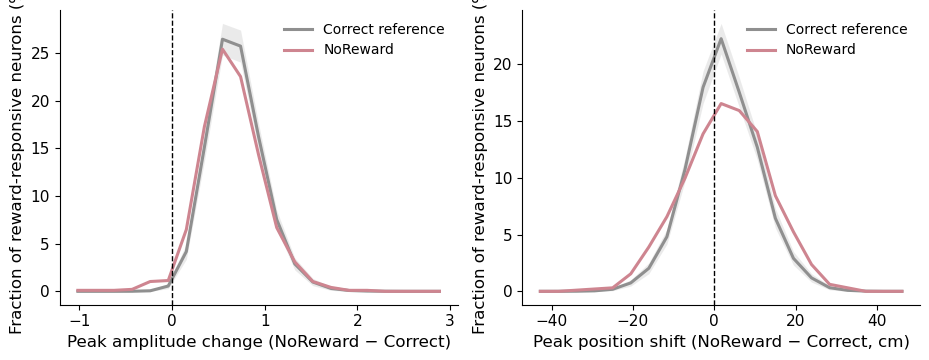

Output()

In [ ]:
if FILE_PATH is None:
    raise ValueError('Set FILE_PATH to one 75% session file before running.')

analysis_results = run_reward_omission_analysis(FILE_PATH)
track_summary = analysis_results['track_summary']
skipped_tracks = analysis_results['skipped_tracks']
reward_table = analysis_results['reward_table']
cell_results = analysis_results['cell_results']
reference_repeats = analysis_results['reference_repeats']
top_amplitude_neurons = analysis_results['top_amplitude_neurons']
top_position_neurons = analysis_results['top_position_neurons']

print(f"file                     : {analysis_results['file_path']}")
print(f"usable tracks            : {len(track_summary)}")
print(f"input unmasked neurons   : {len(reward_table)}")
print(f"reward-responsive neurons: {reward_table.reward_responsive.sum()}")
print(f"valid analyzed neurons   : {len(cell_results)}")
print('\nTrial counts and reward windows')
display(track_summary)

if not skipped_tracks.empty:
    print('\nSkipped tracks')
    display(skipped_tracks)

print('\nLargest absolute peak-amplitude changes')
print('row indices:', top_amplitude_neurons['row_index'].astype(int).tolist())
print('cell IDs   :', top_amplitude_neurons['cell_id'].tolist())
display(top_amplitude_neurons[[
    'row_index',
    'cell_id',
    'reward_p_corrected',
    'significant_tracks',
    'peak_amplitude_change',
    'reference_peak_amplitude_mean',
    'reference_peak_amplitude_std',
]])

print('\nLargest absolute peak-position shifts')
print('row indices:', top_position_neurons['row_index'].astype(int).tolist())
print('cell IDs   :', top_position_neurons['cell_id'].tolist())
display(top_position_neurons[[
    'row_index',
    'cell_id',
    'reward_p_corrected',
    'significant_tracks',
    'peak_position_shift_cm',
    'reference_peak_position_mean_cm',
    'reference_peak_position_std_cm',
]])

feature_distribution_figure = plot_feature_distributions(
    cell_results,
    reference_repeats,
    data=analysis_results['data'],
    
)

if SHOW_INTERACTIVE_BROWSER:
    reward_neuron_browser = browse_reward_omission_neurons(
        analysis_results['data'],
        analysis_results['prepared_tracks'],
        neuron_indices=cell_results['row_index'].tolist(),
    )


Saved figure: /home/wangym/code/ZhaoLab-analysis-python/results/temp/HPC14_2025-05-24_reward_omission_distribution.png


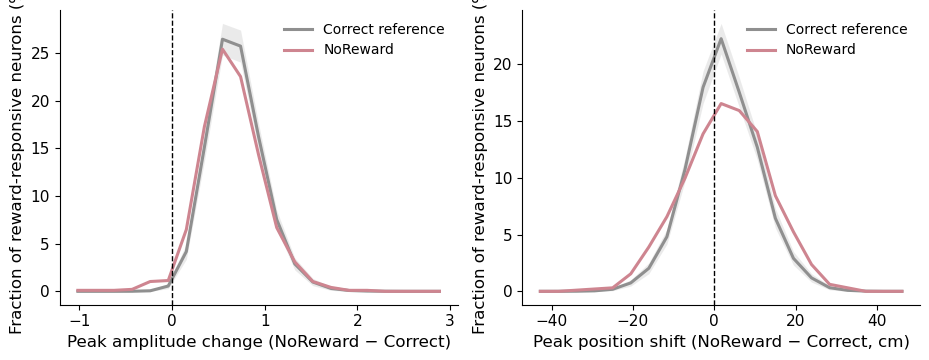

Saved figure: /home/wangym/code/ZhaoLab-analysis-python/results/temp/HPC14_2025-05-24_reward_omission_index-40.pdf


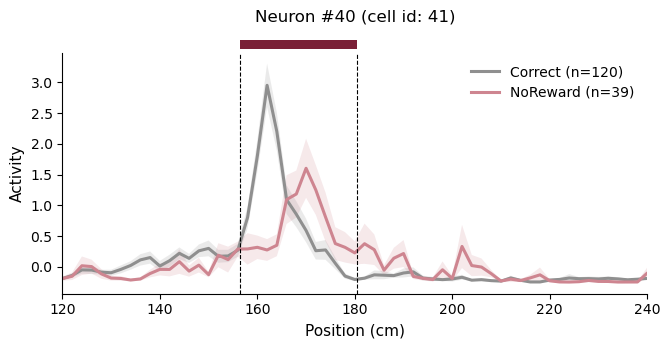

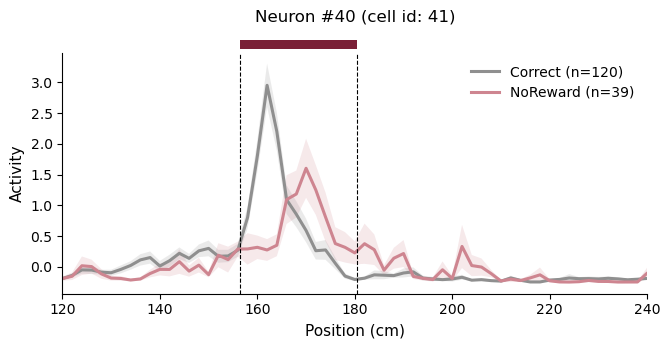

In [114]:
# Save both distribution panels:
plot_reward_omission_distributions(
    analysis_results, savefig=True, save_format='png', dpi=600
)

# Plot and optionally save any row index:
plot_reward_omission_index(
    analysis_results, neuron_index=40, savefig=True, save_format='pdf'
)
# `row_index` is zero-based; `cell_id` is the registered ROI identifier.
